First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Dataset shape: (150, 5)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Model accuracy: 90.0 %

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10



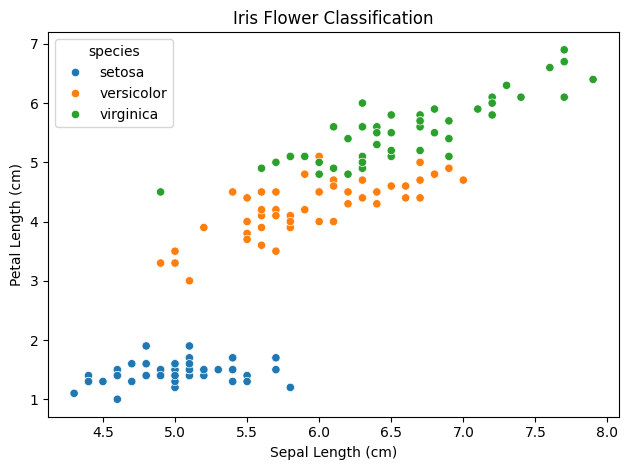

In [1]:

# OIBSIP Data Science Internship
# Task 1: Iris Flower Classification

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load the Iris dataset
iris = load_iris(as_frame=True)
df = iris.frame

# 2. Display the data
print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

# 3. Prepare features and target
X = iris.data
y = iris.target

# 4. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Train the Machine Learning model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 6. Make predictions
y_pred = model.predict(X_test)

# 7. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print("\nModel accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# 8. Visualize the data
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

sns.scatterplot(
    data=df,
    x="sepal length (cm)",
    y="petal length (cm)",
    hue="species"
)

plt.title("Iris Flower Classification")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.tight_layout()
plt.show()
